# Which track characteristics are associated with Spotify popularity?

**Question:** How does Spotify popularity vary across artist, genre and audio-feature groups?

**Method:** Descriptive exploratory analysis with NumPy, Pandas, Matplotlib and Seaborn. No model is trained, so the results are associations, not causes or predictions.

**Group members:** Dion, Mateos, Orkida, Shpëtim

**Data:** [Spotify Tracks Dataset (Kaggle)](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset). Popularity is Spotify's 0–100 score based largely on recent plays. It is **not** a stream count.

## 1. Load the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_FILE = Path('spotify.csv')
if not DATA_FILE.is_file():
    DATA_FILE = Path('spotify-data-analysis/spotify.csv')
OUTPUT_DIR = DATA_FILE.resolve().parent
GROUP_MEMBERS = 'Dion, Mateos, Orkida, Shpëtim'
SOURCE_URL = 'https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset'
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True})

raw = pd.read_csv(DATA_FILE)
print('Raw shape:', raw.shape)
raw.head(3).T

Raw shape: (114000, 21)


,0,1,2
Unnamed: 0,0,1,2
track_id,5SuOikwiRyPMVoIQDJUgSV,4qPNDBW1i3p13qLCt0Ki3A,1iJBSr7s7jYXzM8EGcbK5b
artists,Gen Hoshino,Ben Woodward,Ingrid Michaelson;ZAYN
album_name,Comedy,Ghost (Acoustic),To Begin Again
track_name,Comedy,Ghost - Acoustic,To Begin Again
popularity,73,55,57
duration_ms,230666,149610,210826
explicit,False,False,False
danceability,0.676,0.42,0.438
energy,0.461,0.166,0.359


A row is a **track–genre observation**, so the same `track_id` can appear several times.

| Columns | Meaning |
|---|---|
| `track_id`, `track_name`, `artists`, `album_name` | Track identity |
| `popularity` | Popularity score, 0–100 |
| `danceability`, `energy`, `acousticness`, `instrumentalness`, `speechiness`, `liveness`, `valence` | Audio scores, 0–1 |
| `duration_ms`, `tempo`, `loudness` | Duration, tempo (BPM), loudness (dB) |
| `explicit`, `key`, `mode`, `time_signature` | Flags and categories |
| `track_genre` | Source genre label |

## 2. Hypotheses

- **H1:** Tracks with higher danceability have higher average popularity.
- **H2:** Tracks with higher energy have higher average popularity.
- **H3:** Explicit tracks have higher average popularity than non-explicit tracks.

We compare mean popularity of the top and bottom quartile (H1, H2) and of explicit and non-explicit tracks (H3). These are descriptive comparisons, not significance tests.

## 3. Cleaning

In [2]:
# Drop the exported index and the one row with missing track identity.
missing_identity = raw[['track_id', 'artists', 'album_name', 'track_name']].isna().any(axis=1)
df = raw.drop(columns=['Unnamed: 0']).loc[~missing_identity].copy()

# 'songwriter' and 'singer-songwriter' contain exactly the same track IDs, so merge them.
same_ids = (set(df.loc[df.track_genre.eq('songwriter'), 'track_id'])
            == set(df.loc[df.track_genre.eq('singer-songwriter'), 'track_id']))
assert same_ids
df['track_genre'] = df.track_genre.replace({'songwriter': 'singer-songwriter'})

# Many tracks appear more than once; some repeats have conflicting popularity scores.
per_id = df.groupby('track_id').popularity.agg(['size', 'nunique'])
n_conflicts = int(per_id['nunique'].gt(1).sum())
print(f'Observations: {len(df):,} | unique track IDs: {len(per_id):,} | '
      f'IDs with conflicting popularity: {n_conflicts:,}')

# One row per track_id: first listed genre, median popularity across repeats.
tracks = df.drop_duplicates('track_id').copy()
tracks['popularity'] = tracks.track_id.map(df.groupby('track_id').popularity.median())
tracks['explicit'] = tracks.explicit.astype(int)
tracks['main_artist'] = tracks.artists.str.split(';').str[0].str.strip()

y = tracks.popularity
n_tracks = len(tracks)
print(f'Main sample: {n_tracks:,} tracks | {tracks.main_artist.nunique():,} main artists | '
      f'{tracks.track_genre.nunique()} genres')

Observations: 113,999 | unique track IDs: 89,740 | IDs with conflicting popularity: 720
Main sample: 89,740 tracks | 17,648 main artists | 113 genres


**Cleaning decisions:**

1. Use one row per `track_id`. Conflicting popularity scores are replaced by their **median**, because there are no dates to pick the latest one.
2. Keep each track's first listed genre. This is a convenience label, not a definitive musical genre.
3. Use the first credited artist as the artist group.
4. Keep zero popularity, zero tempo and unusual durations. Unusual values alone do not prove an error.

## 4. Distribution of popularity

,Popularity
count,89740.00
mean,33.20
std,20.58
min,0.00
25%,19.00
50%,33.00
75%,49.00
max,100.00


Popularity 0: 10.5% | popularity >= 70: 3.5%


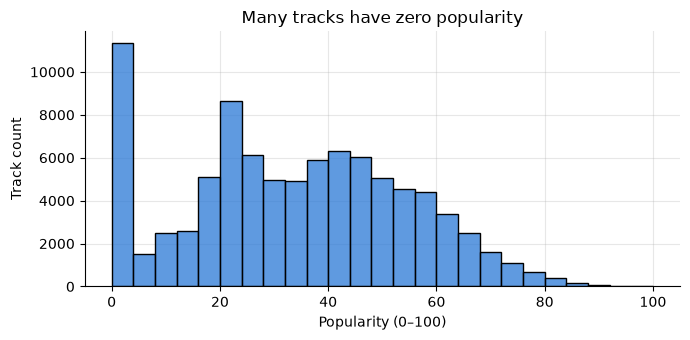

In [3]:
display(y.describe().round(2).to_frame('Popularity'))
print(f'Popularity 0: {y.eq(0).mean():.1%} | popularity >= 70: {y.ge(70).mean():.1%}')

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(y, bins=25, ax=ax, color=BLUE)
ax.set(xlabel='Popularity (0–100)', ylabel='Track count',
       title='Many tracks have zero popularity')
plt.tight_layout()
plt.show()

## 5. What is popularity associated with?

**Pearson correlation** measures a linear association between each audio feature and popularity.

For groups (artist, genre, explicit flag, or ten equal-sized bins of an audio feature) we use **η²**: the share of popularity variation that lies *between* groups. Groupings with many groups (such as artists) look better by chance, so we report the **adjusted η²**, which corrects for the number of groups. It does not correct for confounding, and the values for different groupings overlap and cannot be added.

,Pearson r with popularity
instrumentalness,-0.127
speechiness,-0.047
acousticness,-0.039
duration_ms,-0.023
liveness,-0.014
valence,-0.012
tempo,0.009
energy,0.014
danceability,0.064
loudness,0.072


,Adjusted eta2 (%)
Tempo,0.15
Liveness,0.22
Explicit,0.30
Speechiness,0.38
Valence,0.54
Danceability,0.97
Loudness,0.98
Duration,1.30
Energy,1.35
Instrumentalness,1.74


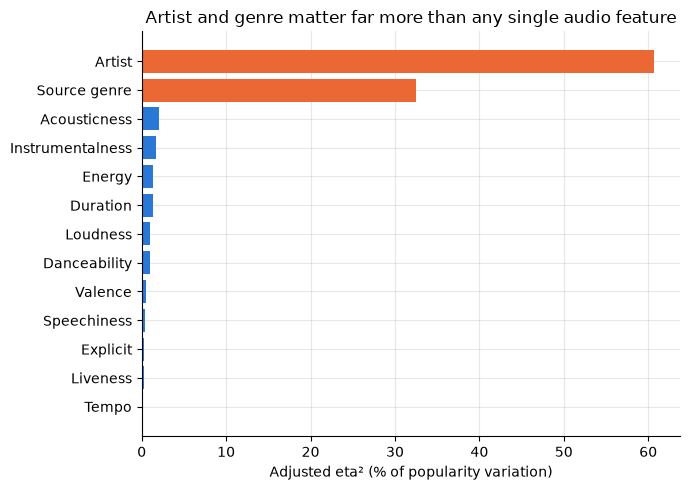

In [4]:
audio_cols = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
              'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']
corr = tracks[audio_cols].corrwith(y)
valid_tempo = tracks.tempo.gt(0)                      # zero tempo means "not estimated"
corr['tempo'] = tracks.loc[valid_tempo, 'tempo'].corr(y[valid_tempo])
display(corr.sort_values().round(3).to_frame('Pearson r with popularity'))

def adjusted_eta2(target, groups):
    """Share of variance between groups, adjusted for the number of groups."""
    n, k = len(target), groups.nunique()
    group_mean = target.groupby(groups, observed=True).transform('mean')
    eta2 = ((group_mean - target.mean()) ** 2).sum() / ((target - target.mean()) ** 2).sum()
    return 1 - (1 - eta2) * (n - 1) / (n - k)

def quantile_groups(values):
    return pd.qcut(values, 10, duplicates='drop')

groupings = {'Artist': tracks.main_artist, 'Source genre': tracks.track_genre,
             'Explicit': tracks.explicit}
groupings.update({col.replace('_ms', '').capitalize(): quantile_groups(tracks[col]) for col in audio_cols})
main_effects = pd.Series({name: 100 * adjusted_eta2(y, g) for name, g in groupings.items()},
                         name='Adjusted eta2 (%)').sort_values()
display(main_effects.round(2).to_frame())

fig, ax = plt.subplots(figsize=(7, 5))
colors = [ORANGE if k in ('Artist', 'Source genre') else BLUE for k in main_effects.index]
ax.barh(main_effects.index, main_effects, color=colors)
ax.set(xlabel='Adjusted eta² (% of popularity variation)',
       title='Artist and genre matter far more than any single audio feature')
plt.tight_layout()
plt.show()

### How the audio features relate to each other

The audio measurements overlap strongly (for example energy, loudness and acousticness). This shows how the features covary, **not** their relationship with popularity.

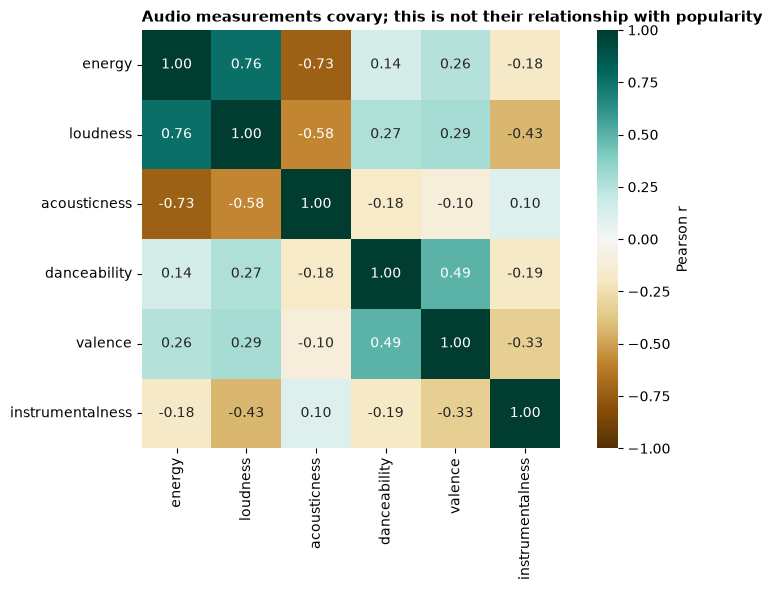

In [5]:
group_cols = ['energy', 'loudness', 'acousticness', 'danceability', 'valence', 'instrumentalness']
fig, ax = plt.subplots(figsize=(8.4, 6))
sns.heatmap(tracks[group_cols].corr(), ax=ax, cmap='BrBG', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', square=True, cbar_kws={'label': 'Pearson r'})
ax.set_title('Audio measurements covary; this is not their relationship with popularity',
             loc='left', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

### Genre differences

Mean popularity for the eight least and eight most popular genres (each track counted once, by its first genre).

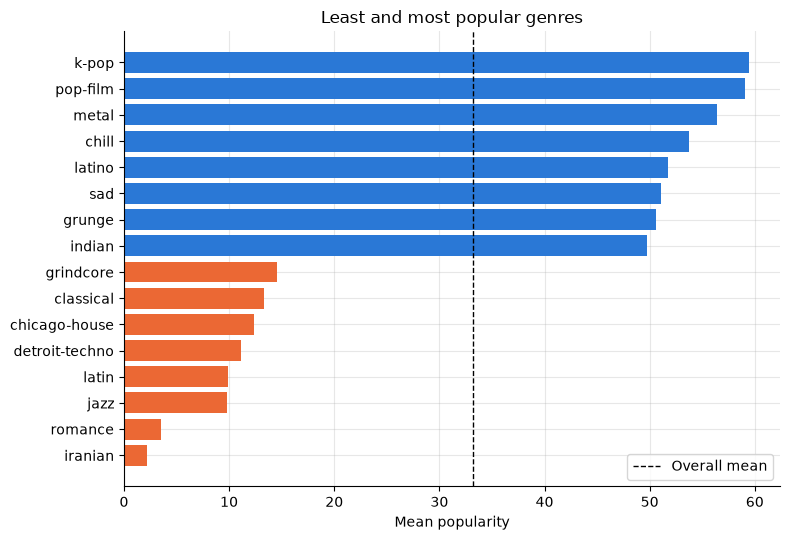

In [6]:
genre_mean = tracks.groupby('track_genre').popularity.agg(['count', 'mean']).sort_values('mean')
extremes = pd.concat([genre_mean.head(8), genre_mean.tail(8)])

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(extremes.index, extremes['mean'], color=[ORANGE] * 8 + [BLUE] * 8)
ax.axvline(y.mean(), color='black', ls='--', lw=1, label='Overall mean')
ax.set(xlabel='Mean popularity', title='Least and most popular genres')
ax.legend()
plt.tight_layout()
plt.show()

### Overall versus within-genre correlations

Subtracting each genre's mean from both the feature and popularity removes differences *between* genres. If a correlation shrinks, genre composition explains part of the overall association. This is not a causal adjustment.

In [7]:
within_cols = ['instrumentalness', 'acousticness', 'danceability', 'energy']
by_genre = tracks.groupby('track_genre')
within = pd.DataFrame({
    'Overall': tracks[within_cols].corrwith(y),
    'Within genre': (tracks[within_cols] - by_genre[within_cols].transform('mean')).corrwith(
        y - by_genre.popularity.transform('mean')),
})
display(within.round(3))

,Overall,Within genre
instrumentalness,-0.127,-0.015
acousticness,-0.039,-0.021
danceability,0.064,0.029
energy,0.014,-0.012


## 6. Evaluate the hypotheses

In [8]:
rows = {}
for name, col in [('H1', 'danceability'), ('H2', 'energy')]:
    low, high = tracks[col].quantile([.25, .75])
    bottom, top = y[tracks[col].le(low)], y[tracks[col].ge(high)]
    rows[name] = {'feature': col, 'comparison': 'top minus bottom quartile',
                  'mean popularity (reference)': bottom.mean(), 'mean popularity (comparison)': top.mean(),
                  'difference': top.mean() - bottom.mean(), 'Pearson r': tracks[col].corr(y)}
no, yes = y[tracks.explicit.eq(0)], y[tracks.explicit.eq(1)]
rows['H3'] = {'feature': 'explicit', 'comparison': 'explicit minus not explicit',
              'mean popularity (reference)': no.mean(), 'mean popularity (comparison)': yes.mean(),
              'difference': yes.mean() - no.mean(), 'Pearson r': tracks.explicit.corr(y)}
hypotheses = pd.DataFrame(rows).T
hypotheses[hypotheses.columns[2:]] = hypotheses[hypotheses.columns[2:]].astype(float)
display(hypotheses.round(3))

,feature,comparison,mean popularity (reference),mean popularity (comparison),difference,Pearson r
H1,danceability,top minus bottom quartile,30.484,33.565,3.082,0.064
H2,energy,top minus bottom quartile,31.425,31.231,-0.194,0.014
H3,explicit,explicit minus not explicit,32.852,36.884,4.032,0.055


- **H1 (danceability):** weakly supported. The top quartile is only slightly more popular.
- **H2 (energy):** not supported. The top and bottom quartiles have almost the same mean popularity.
- **H3 (explicit):** supported as an unadjusted association. Explicit tracks have a higher mean.

## 7. Conclusion and limits

**Answer:** In this dataset, popularity varies much more across **artist and genre groups** than across any single audio feature. Within genres, the audio correlations shrink further (especially instrumentalness), so part of the pooled association is genre composition.

**Limits:**

- **Fixed genre quotas:** the dataset has the same number of rows for every genre, so it does not represent Spotify's catalogue or listening.
- **Repeated and conflicting scores:** we use the median score per track; no dates are available to choose the latest.
- **Artist groups are small:** many artists have only a few tracks, which is why we use the adjusted η².
- **Descriptive only:** no causes, no predictions. The file has no release dates, streams or marketing information.

## 8. Poster

Three graphs summarise the findings: a **horizontal bar chart** (what explains popularity), a **scatter chart** (H1 and H2) and an annotated **heatmap** (overall versus within-genre correlation). The poster reuses the objects computed above and is saved as PDF and PNG.

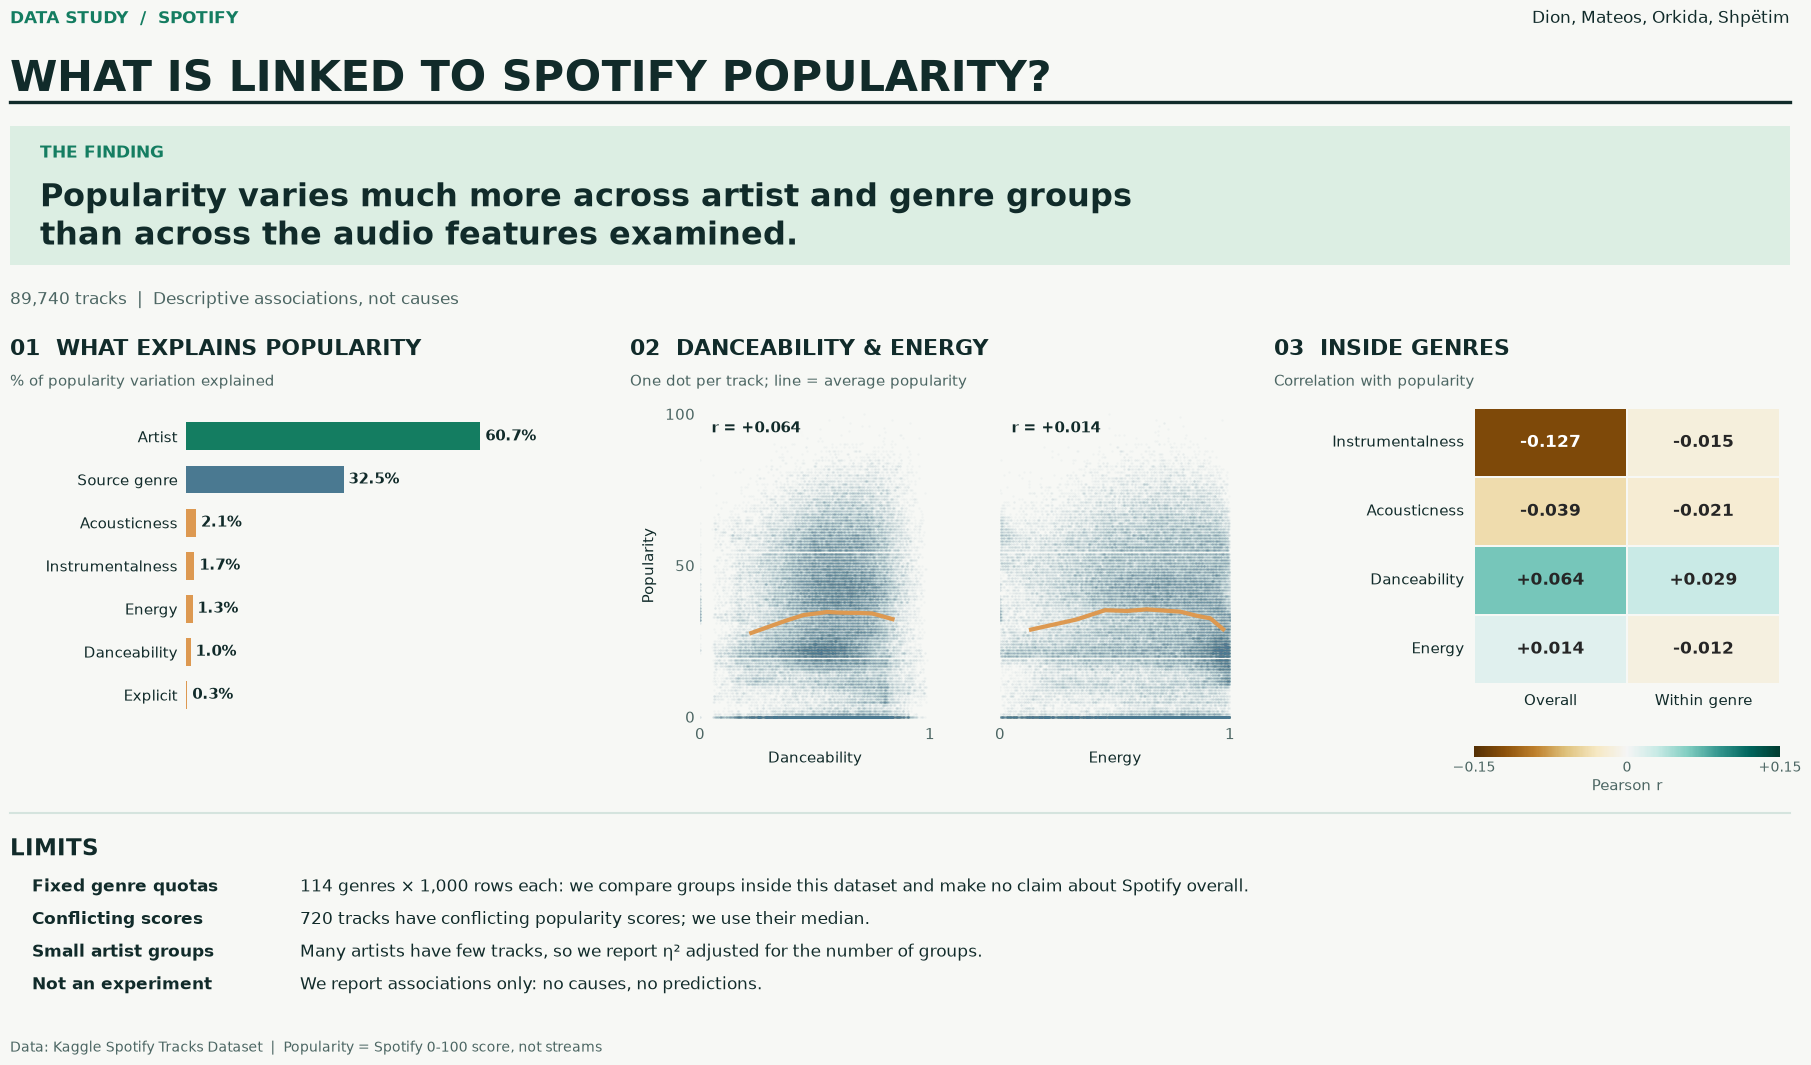

Wrote: /Users/shpetimshabanaj/Development/Holberton/spotify-data-analysis/Spotify_Popularity_Poster_From_Notebook.pdf and /Users/shpetimshabanaj/Development/Holberton/spotify-data-analysis/Spotify_Popularity_Poster_From_Notebook.png


In [9]:
PDF_FILE = OUTPUT_DIR / 'Spotify_Popularity_Poster_From_Notebook.pdf'
PNG_FILE = OUTPUT_DIR / 'Spotify_Popularity_Poster_From_Notebook.png'
DARK, GREEN, BLUE_P = '#112B2A', '#147D61', '#4A7991'
GOLD, SUB, FAINT, BG = '#DD9951', '#4C6663', '#D5E4DE', '#F7F8F5'
fig = plt.figure(figsize=(20, 11.25), facecolor=BG)

fig.text(.055, .964, 'DATA STUDY  /  SPOTIFY', fontsize=12.6, weight='bold', color=GREEN, va='top')
fig.text(.055, .921, 'WHAT IS LINKED TO SPOTIFY POPULARITY?', fontsize=31,
         weight='bold', color=DARK, va='top')
fig.text(.945, .964, GROUP_MEMBERS, fontsize=12.3, color=DARK, ha='right', va='top')
fig.add_artist(plt.Line2D([.055, .945], [.882, .882], lw=2.4, color=DARK, transform=fig.transFigure))
fig.add_artist(plt.Rectangle((.055, .737), .890, .124, transform=fig.transFigure,
                             facecolor='#DCEEE3', edgecolor='none'))
fig.text(.070, .844, 'THE FINDING', fontsize=12, weight='bold', color=GREEN, va='top')
fig.text(.070, .811, 'Popularity varies much more across artist and genre groups',
         fontsize=23, weight='bold', va='top', color=DARK)
fig.text(.070, .777, 'than across the audio features examined.',
         fontsize=23, weight='bold', va='top', color=DARK)
fig.text(.055, .714, f'{n_tracks:,} tracks  |  Descriptive associations, not causes',
         fontsize=12, color=SUB, va='top')

for x, title, subtitle in [
    (.055, '01  WHAT EXPLAINS POPULARITY', '% of popularity variation explained'),
    (.365, '02  DANCEABILITY & ENERGY', 'One dot per track; line = average popularity'),
    (.687, '03  INSIDE GENRES', 'Correlation with popularity'),
]:
    fig.text(x, .672, title, fontsize=15.8, weight='bold', color=DARK, va='top')
    fig.text(x, .640, subtitle, fontsize=10.7, color=SUB, va='top')

# Chart 1: horizontal bars with values printed on them.
score = main_effects[['Artist', 'Source genre', 'Explicit', 'Danceability', 'Energy',
                      'Acousticness', 'Instrumentalness']].sort_values()
bar_colors = [GREEN if k == 'Artist' else BLUE_P if k == 'Source genre' else GOLD for k in score.index]
a = fig.add_axes([.143, .330, .177, .280], facecolor=BG)
a.barh(score.index, score.values, color=bar_colors, height=.65)
a.set(xlim=(0, 73))
a.set_xticks([])
a.tick_params(axis='y', labelsize=11, colors=DARK, length=0, pad=6)
a.grid(False)
a.spines[:].set_visible(False)
for i, value in enumerate(score):
    a.text(value + 1, i, f'{value:.1f}%', va='center', fontsize=11, weight='bold', color=DARK)

# Chart 2: popularity against danceability (H1) and energy (H2); gold line = mean per decile.
scatter_axes = []
for left, key, feature, label in [(.400, 'H1', 'danceability', 'Danceability'),
                                  (.550, 'H2', 'energy', 'Energy')]:
    s_ax = fig.add_axes([left, .330, .115, .280], facecolor=BG,
                        sharey=scatter_axes[0] if scatter_axes else None)
    s_ax.scatter(tracks[feature], y, s=3, color=BLUE_P, alpha=.045, linewidths=0,
                 rasterized=True, zorder=2)
    trend = tracks.groupby(quantile_groups(tracks[feature]), observed=True).agg(
        feature_mean=(feature, 'mean'), popularity_mean=('popularity', 'mean'))
    s_ax.plot(trend.feature_mean, trend.popularity_mean, color=GOLD, lw=3, zorder=4)
    s_ax.text(.05, .96, f'r = {hypotheses.loc[key, "Pearson r"]:+.3f}', transform=s_ax.transAxes,
              va='top', fontsize=11, weight='bold', color=DARK,
              bbox={'facecolor': BG, 'edgecolor': 'none', 'alpha': .85, 'pad': 2.5}, zorder=5)
    s_ax.set(xlim=(0, 1), ylim=(-2, 102), xticks=[0, 1], yticks=[0, 50, 100])
    s_ax.set_xlabel(label, fontsize=11, color=DARK, labelpad=6)
    s_ax.tick_params(axis='both', labelsize=10.5, colors=SUB, length=0)
    s_ax.grid(False)
    s_ax.spines[:].set_visible(False)
    scatter_axes.append(s_ax)
scatter_axes[0].set_ylabel('Popularity', fontsize=11, color=DARK, labelpad=6)
scatter_axes[1].tick_params(axis='y', labelleft=False)

# Chart 3: heatmap, overall vs within-genre correlation on one zero-centred colour scale.
c = fig.add_axes([.787, .365, .153, .245], facecolor=BG)
color_scale = fig.add_axes([.787, .300, .153, .010], facecolor=BG)
sns.heatmap(within[['Overall', 'Within genre']], ax=c, cbar_ax=color_scale,
            cmap='BrBG', center=0, vmin=-.15, vmax=.15,
            annot=True, fmt='+.3f', annot_kws={'fontsize': 12, 'weight': 'bold'},
            linewidths=1.2, linecolor=BG,
            cbar_kws={'orientation': 'horizontal', 'ticks': [-.15, 0, .15]})
c.set(xlabel='', ylabel='')
c.tick_params(axis='both', labelsize=11, colors=DARK, length=0, pad=7)
c.set_xticklabels(['Overall', 'Within genre'], rotation=0)
c.set_yticklabels(['Instrumentalness', 'Acousticness', 'Danceability', 'Energy'], rotation=0)
c.grid(False)
color_scale.set_xticklabels(['−0.15', '0', '+0.15'])
color_scale.tick_params(labelsize=10, colors=SUB, length=0, pad=3)
color_scale.set_xlabel('Pearson r', fontsize=10.5, color=SUB, labelpad=3)
color_scale.grid(False)

fig.add_artist(plt.Line2D([.055, .945], [.250, .250], lw=1.5, color=FAINT, transform=fig.transFigure))
fig.text(.055, .228, 'LIMITS', fontsize=16.5, weight='bold', color=DARK, va='top')

genre_quota = raw.groupby('track_genre').size()
limits = [
    ('Fixed genre quotas',
     f'{len(genre_quota)} genres × {int(genre_quota.iloc[0]):,} rows each: we compare groups inside this '
     'dataset and make no claim about Spotify overall.'),
    ('Conflicting scores',
     f'{n_conflicts:,} tracks have conflicting popularity scores; we use their median.'),
    ('Small artist groups',
     'Many artists have few tracks, so we report η² adjusted for the number of groups.'),
    ('Not an experiment',
     'We report associations only: no causes, no predictions.'),
]
for pos, (lead, text) in zip([.192, .163, .134, .105], limits):
    fig.text(.066, pos, lead, fontsize=12.3, weight='bold', color=DARK, va='top')
    fig.text(.200, pos, text, fontsize=12.3, color=DARK, va='top')
fig.text(.055, .035, 'Data: Kaggle Spotify Tracks Dataset  |  Popularity = Spotify 0-100 score, not streams',
         fontsize=10.1, color=SUB, va='bottom', url=SOURCE_URL)

fig.savefig(PDF_FILE, facecolor=BG, bbox_inches=None)
fig.savefig(PNG_FILE, dpi=160, facecolor=BG, bbox_inches=None)
plt.show()
plt.close(fig)
print('Wrote:', PDF_FILE, 'and', PNG_FILE)